In [1]:

import os
import json
import random
import pickle
import datetime

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

import kagglehub


2026-10-27 02:34:35.842815: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793068476.092670      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793068476.164080      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793068476.819920      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793068476.819963      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793068476.819966      57 computation_placer.cc:177] computation placer alr

In [2]:
SEEDS = [42, 123, 2024, 3407, 777]

BATCH_SIZE = 32
EPOCHS = 50
PATIENCE = 5
IMAGE_SIZE = (224, 224)
LEARNING_RATE = 1e-5
FINE_TUNE_LAYERS = 20
AUTOTUNE = tf.data.AUTOTUNE

EXPERIMENT_NAME = "Resnet3classplantvillage"
EXPECTED_NUM_CLASSES = 3


In [3]:
dataset_path = kagglehub.dataset_download("faysalmiah1721758/potato-dataset")
DATASET_DIR = dataset_path

print("Dataset directory:", DATASET_DIR)


Dataset directory: /kaggle/input/datasets/faysalmiah1721758/potato-dataset


In [4]:
class_names = sorted([
    folder for folder in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, folder))
])

NUM_CLASSES = len(class_names)

print("Detected classes:")
for i, class_name in enumerate(class_names):
    print(f"{i}: {class_name}")

print("Number of classes:", NUM_CLASSES)

assert NUM_CLASSES == EXPECTED_NUM_CLASSES, f"Expected {EXPECTED_NUM_CLASSES}, found {NUM_CLASSES}"


Detected classes:
0: Potato___Early_blight
1: Potato___Late_blight
2: Potato___healthy
Number of classes: 3


In [5]:
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

file_paths = []
labels = []

for label_index, class_name in enumerate(class_names):
    class_dir = os.path.join(DATASET_DIR, class_name)

    for fname in os.listdir(class_dir):
        if fname.lower().endswith(valid_extensions):
            file_paths.append(os.path.join(class_dir, fname))
            labels.append(label_index)

file_paths = np.array(file_paths)
labels = np.array(labels)

print("Total images:", len(labels))

unique, counts = np.unique(labels, return_counts=True)
print("\nClass distribution:")
for idx, count in zip(unique, counts):
    print(f"{class_names[idx]}: {count}")


Total images: 2152

Class distribution:
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152


In [6]:

# ============================================================
# ResNet-50: Dataset Loading and Preprocessing
# ============================================================

def load_dataset_resnet50(file_paths, labels, augment=False, shuffle=True, seed=None):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))

    def process(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )
        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMAGE_SIZE)
        image = tf.cast(image, tf.float32)

        if augment:
            image = tf.image.random_flip_left_right(image)
            image = tf.image.random_brightness(image, max_delta=25.5)
            image = tf.image.random_contrast(
                image,
                lower=0.9,
                upper=1.1
            )
            image = tf.clip_by_value(image, 0.0, 255.0)

        # ResNet-50 ImageNet preprocessing
        # Input pixels must remain in the 0-255 range.
        image = preprocess_input(image)

        label = tf.one_hot(label, depth=NUM_CLASSES)

        return image, label

    ds = ds.map(process, num_parallel_calls=AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(file_paths),
            seed=seed,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return ds


In [7]:

# ============================================================
# ResNet-50: Three-Class Fine-Tuned Model
# ============================================================

def build_resnet50(num_classes, input_shape=(224, 224, 3)):
    inputs = tf.keras.Input(shape=input_shape)

    backbone = ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    backbone.trainable = True

    # Fine-tune the last specified number of layers
    for layer in backbone.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False

    # Keep BatchNormalization statistics fixed
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    x = backbone.output

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="ResNet50_3class_finetuned"
    )

    return model


In [8]:
def count_model_parameters(model):
    total_params = model.count_params()

    trainable_params = np.sum([
        np.prod(v.shape) for v in model.trainable_weights
    ])

    non_trainable_params = np.sum([
        np.prod(v.shape) for v in model.non_trainable_weights
    ])

    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Non-trainable parameters: {non_trainable_params:,}")

    return total_params, trainable_params, non_trainable_params


In [9]:

# ============================================================
# ResNet-50: Run One Seed (Three-Class Classification)
# ============================================================

def run_single_seed(seed):
    print("\n" + "=" * 70)
    print(f"Running ResNet-50 | Seed: {seed}")
    print("=" * 70)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    # --------------------------------------------------------
    # Stratified train / validation / test split (80/10/10)
    # --------------------------------------------------------
    X_train, X_temp, y_train, y_temp = train_test_split(
        file_paths,
        labels,
        test_size=0.20,
        stratify=labels,
        random_state=seed
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=seed
    )

    print(f"Train: {len(X_train)}")
    print(f"Validation: {len(X_val)}")
    print(f"Test: {len(X_test)}")

    # --------------------------------------------------------
    # Class weights
    # --------------------------------------------------------
    class_weight_vals = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(NUM_CLASSES),
        y=y_train
    )
    class_weight = dict(enumerate(class_weight_vals))

    print("Class weights:", class_weight)

    # --------------------------------------------------------
    # TensorFlow datasets
    # --------------------------------------------------------
    train_ds = load_dataset_resnet50(
        X_train, y_train,
        augment=True, shuffle=True, seed=seed
    )

    val_ds = load_dataset_resnet50(
        X_val, y_val,
        augment=False, shuffle=False, seed=seed
    )

    test_ds = load_dataset_resnet50(
        X_test, y_test,
        augment=False, shuffle=False, seed=seed
    )

    # --------------------------------------------------------
    # Build ResNet-50
    # --------------------------------------------------------
    model = build_resnet50(num_classes=NUM_CLASSES)

    total_params, trainable_params, non_trainable_params = (
        count_model_parameters(model)
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # --------------------------------------------------------
    # Output directories and filenames
    # --------------------------------------------------------
    os.makedirs("models", exist_ok=True)
    os.makedirs("history", exist_ok=True)
    os.makedirs("reports", exist_ok=True)
    os.makedirs("predictions", exist_ok=True)

    run_name = f"{EXPERIMENT_NAME}_{NUM_CLASSES}class_seed_{seed}"

    model_path = f"models/{run_name}.keras"
    history_path = f"history/{run_name}_history.pkl"
    plot_path = f"history/{run_name}_accuracy_loss.png"
    cm_path = f"history/{run_name}_confusion_matrix.png"
    report_path = f"reports/{run_name}_classification_report.json"
    predictions_path = f"predictions/{run_name}_test_predictions.csv"

    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    checkpoint = ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stop, checkpoint],
        class_weight=class_weight
    )

    stopped_epoch = len(history.history["loss"])
    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    with open(history_path, "wb") as f:
        pickle.dump(history.history, f)

    # --------------------------------------------------------
    # Test evaluation
    # --------------------------------------------------------
    test_loss, test_acc = model.evaluate(
        test_ds,
        verbose=0
    )

    # Predict once, preserving test-set order
    probabilities = model.predict(
        test_ds,
        verbose=0
    )

    y_true = np.asarray(y_test, dtype=int)
    y_pred = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    assert len(probabilities) == len(X_test)
    assert probabilities.shape[1] == NUM_CLASSES

    # --------------------------------------------------------
    # Save per-image predictions and probabilities
    # --------------------------------------------------------
    predictions_df = pd.DataFrame({
        "file_path": X_test,
        "true_label": y_true,
        "predicted_label": y_pred,
        "confidence": confidence,
        "correct": (y_true == y_pred).astype(int)
    })

    for class_idx in range(NUM_CLASSES):
        predictions_df[f"prob_class_{class_idx}"] = (
            probabilities[:, class_idx]
        )

    predictions_df.to_csv(
        predictions_path,
        index=False
    )

    print("Saved test predictions:", predictions_path)

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------
    report_dict = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        output_dict=True,
        zero_division=0
    )

    with open(report_path, "w") as f:
        json.dump(report_dict, f, indent=4)

    print(f"\nSeed {seed} Test Accuracy: {test_acc:.4f}")
    print(f"Seed {seed} Test Loss: {test_loss:.4f}")
    print(f"Seed {seed} Stopped Epoch: {stopped_epoch}")
    print(f"Seed {seed} Best Epoch: {best_epoch}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    fig, ax = plt.subplots(figsize=(8, 8))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45
    )

    plt.title(f"ResNet-50 Confusion Matrix - Seed {seed}")
    plt.tight_layout()
    plt.savefig(cm_path, dpi=300)
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # Training curves
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 5)
    )

    axes[0].plot(
        history.history["accuracy"],
        label="Train Accuracy"
    )
    axes[0].plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )
    axes[0].set_title(f"Accuracy - Seed {seed}")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(
        history.history["loss"],
        label="Train Loss"
    )
    axes[1].plot(
        history.history["val_loss"],
        label="Validation Loss"
    )
    axes[1].set_title(f"Loss - Seed {seed}")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(plot_path, dpi=300)
    plt.show()
    plt.close(fig)

    # --------------------------------------------------------
    # Return seed-level results
    # --------------------------------------------------------
    return {
        "seed": seed,
        "num_classes": NUM_CLASSES,
        "test_accuracy": float(test_acc),
        "test_loss": float(test_loss),
        "stopped_epoch": stopped_epoch,
        "best_epoch": best_epoch,
        "macro_precision": report_dict["macro avg"]["precision"],
        "macro_recall": report_dict["macro avg"]["recall"],
        "macro_f1": report_dict["macro avg"]["f1-score"],
        "weighted_precision": report_dict["weighted avg"]["precision"],
        "weighted_recall": report_dict["weighted avg"]["recall"],
        "weighted_f1": report_dict["weighted avg"]["f1-score"],
        "total_params": int(total_params),
        "trainable_params": int(trainable_params),
        "non_trainable_params": int(non_trainable_params),
        "model_path": model_path,
        "history_path": history_path,
        "plot_path": plot_path,
        "confusion_matrix_path": cm_path,
        "classification_report_path": report_path,
        "predictions_path": predictions_path
    }



Running ResNet-50 | Seed: 42
Train: 1721
Validation: 215
Test: 216
Class weights: {0: np.float64(0.7170833333333333), 1: np.float64(0.7170833333333333), 2: np.float64(4.741046831955923)}


I0000 00:00:1793068749.662857      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793068749.665728      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters: 23,593,859
Trainable parameters: 8,925,187
Non-trainable parameters: 14,668,672
Epoch 1/50


I0000 00:00:1793068838.812908     153 service.cc:152] XLA service 0x7f8af4115090 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793068838.812954     153 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793068838.812962     153 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793068840.909834     153 cuda_dnn.cc:529] Loaded cuDNN version 91002


 1/54 ━━━━━━━━━━━━━━━━━━━━ 1:22:48 94s/step - accuracy: 0.3125 - loss: 1.1174

I0000 00:00:1793068848.923289     153 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


54/54 ━━━━━━━━━━━━━━━━━━━━ 121s 516ms/step - accuracy: 0.5285 - loss: 1.2336 - val_accuracy: 0.9442 - val_loss: 0.1504
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 135ms/step - accuracy: 0.9292 - loss: 0.1750 - val_accuracy: 0.9721 - val_loss: 0.0842
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 135ms/step - accuracy: 0.9670 - loss: 0.0811 - val_accuracy: 0.9814 - val_loss: 0.0467
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 115ms/step - accuracy: 0.9914 - loss: 0.0326 - val_accuracy: 0.9767 - val_loss: 0.0603
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 117ms/step - accuracy: 0.9848 - loss: 0.0222 - val_accuracy: 0.9814 - val_loss: 0.0593
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 139ms/step - accuracy: 0.9969 - loss: 0.0160 - val_accuracy: 0.9860 - val_loss: 0.0371
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 120ms/step - accuracy: 0.9953 - loss: 0.0147 - val_accuracy: 0.9767 - val_loss: 0.0541
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 122ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 0.9767 -

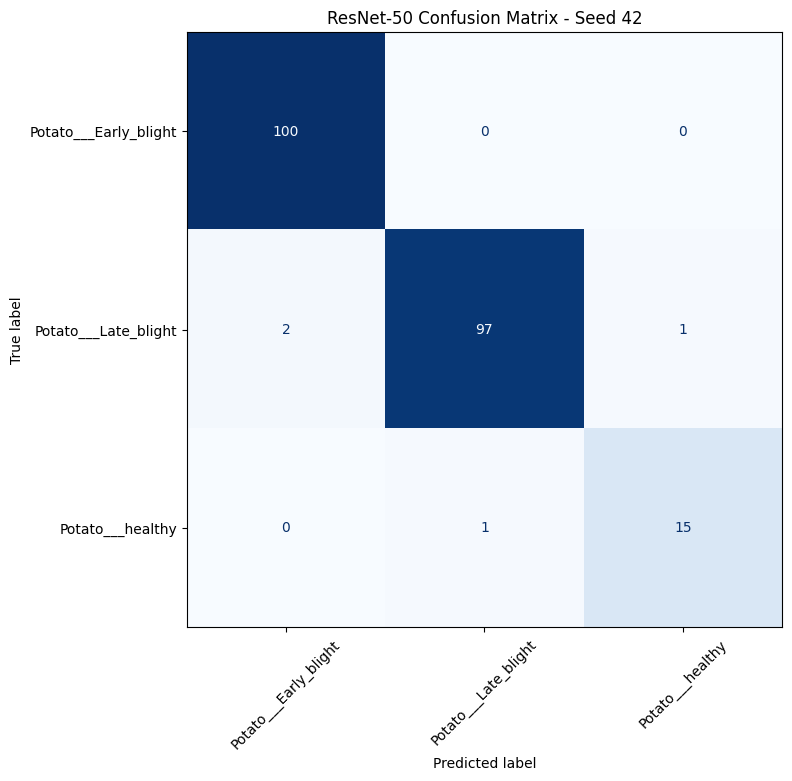

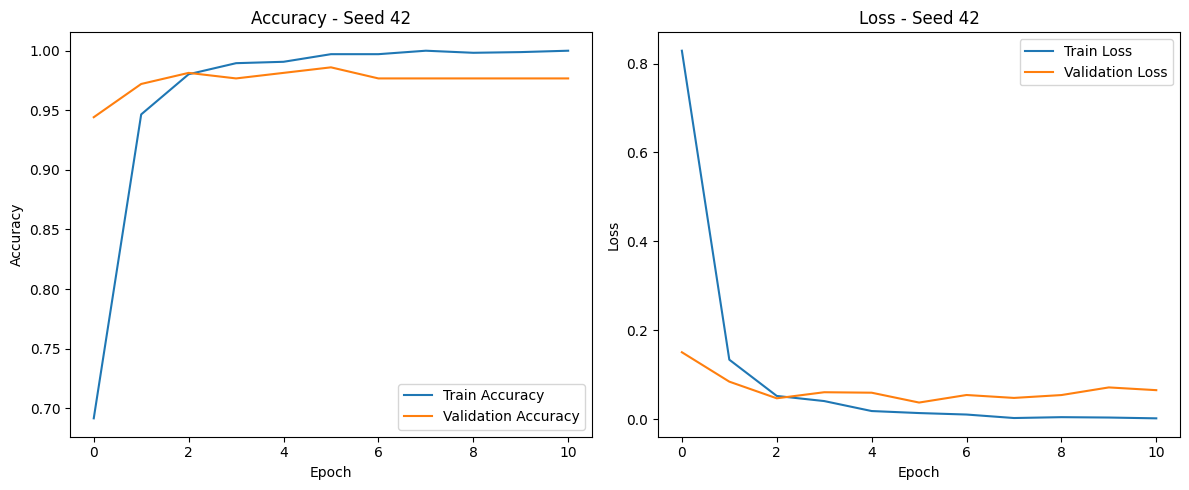


Running ResNet-50 | Seed: 123
Train: 1721
Validation: 215
Test: 216
Class weights: {0: np.float64(0.7170833333333333), 1: np.float64(0.7170833333333333), 2: np.float64(4.741046831955923)}
Total parameters: 23,593,859
Trainable parameters: 8,925,187
Non-trainable parameters: 14,668,672
Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 336ms/step - accuracy: 0.5523 - loss: 0.9117 - val_accuracy: 0.8977 - val_loss: 0.2564
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.9315 - loss: 0.1299 - val_accuracy: 0.9488 - val_loss: 0.1131
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 147ms/step - accuracy: 0.9785 - loss: 0.0493 - val_accuracy: 0.9674 - val_loss: 0.0653
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 146ms/step - accuracy: 0.9852 - loss: 0.0307 - val_accuracy: 0.9674 - val_loss: 0.0533
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 121ms/step - accuracy: 0.9907 - loss: 0.0167 - val_accuracy: 0.9721 - val_loss: 0.0536
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 121ms/step - accuracy: 0.999

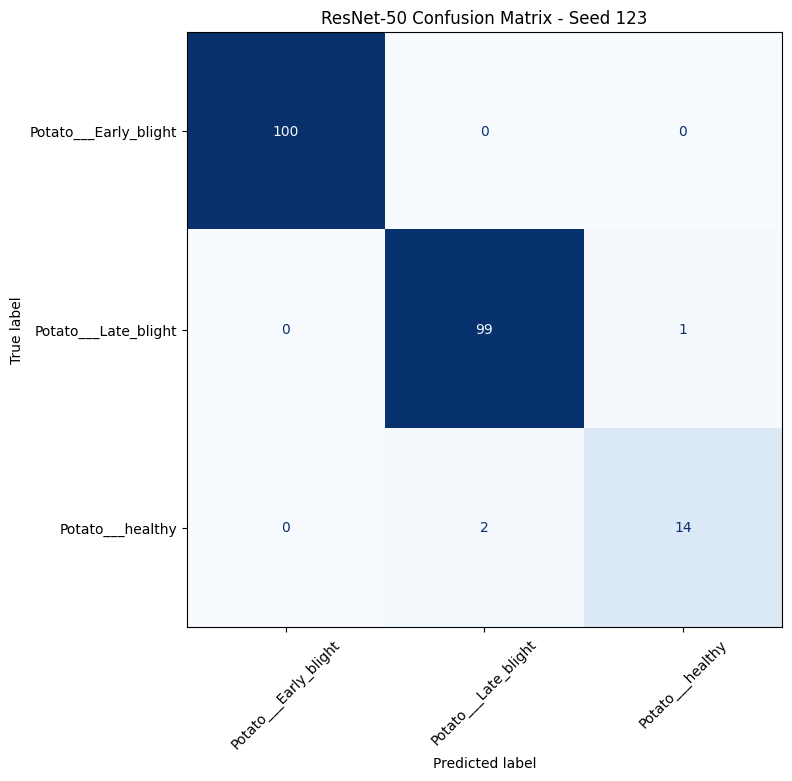

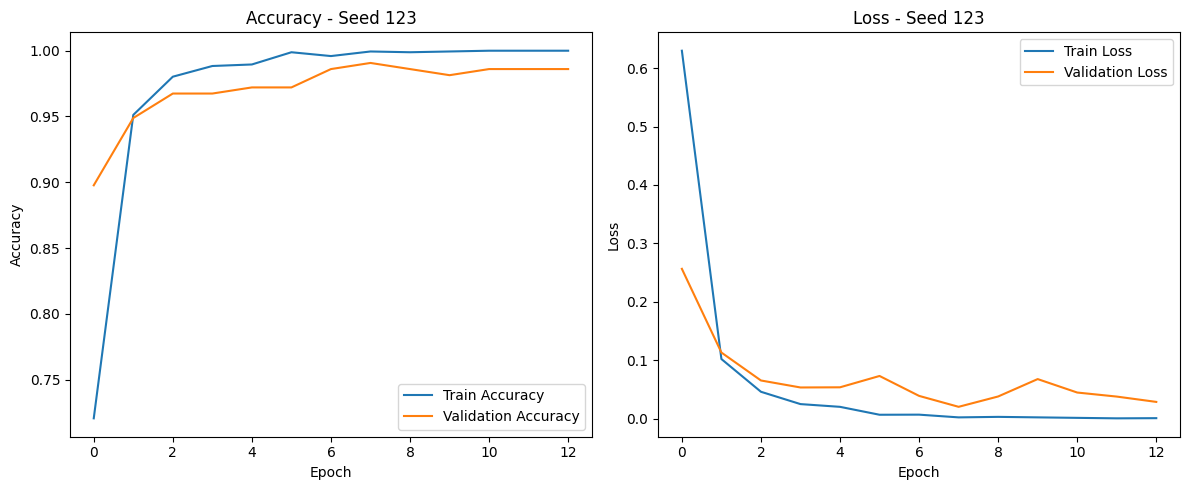


Running ResNet-50 | Seed: 2024
Train: 1721
Validation: 215
Test: 216
Class weights: {0: np.float64(0.7170833333333333), 1: np.float64(0.7170833333333333), 2: np.float64(4.741046831955923)}
Total parameters: 23,593,859
Trainable parameters: 8,925,187
Non-trainable parameters: 14,668,672
Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 337ms/step - accuracy: 0.4939 - loss: 0.9929 - val_accuracy: 0.9488 - val_loss: 0.1785
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.9418 - loss: 0.1585 - val_accuracy: 0.9860 - val_loss: 0.0466
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 146ms/step - accuracy: 0.9802 - loss: 0.0554 - val_accuracy: 0.9860 - val_loss: 0.0423
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 145ms/step - accuracy: 0.9920 - loss: 0.0308 - val_accuracy: 0.9860 - val_loss: 0.0366
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 142ms/step - accuracy: 0.9938 - loss: 0.0198 - val_accuracy: 0.9860 - val_loss: 0.0254
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - accuracy: 0.

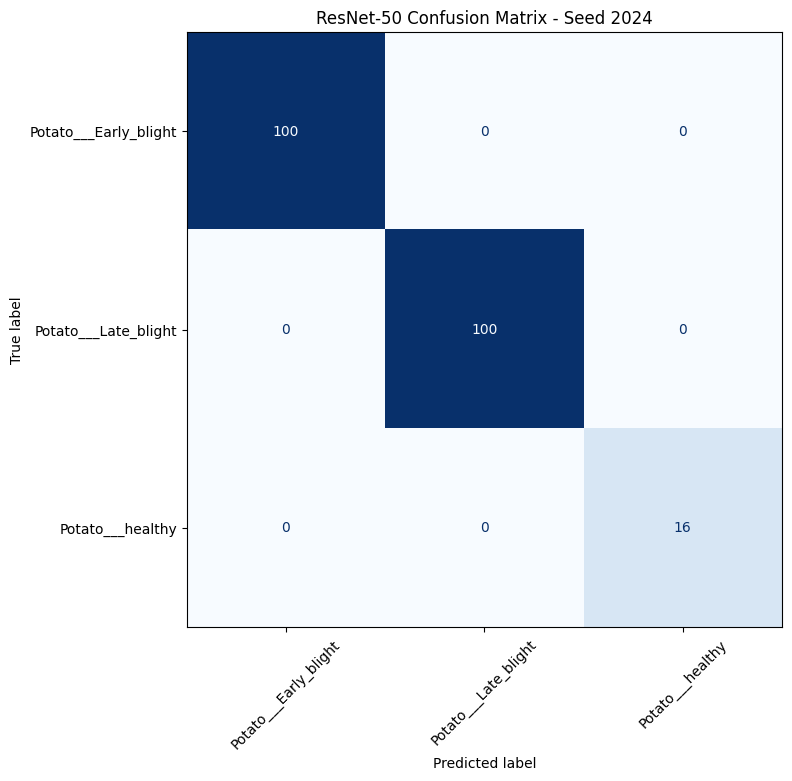

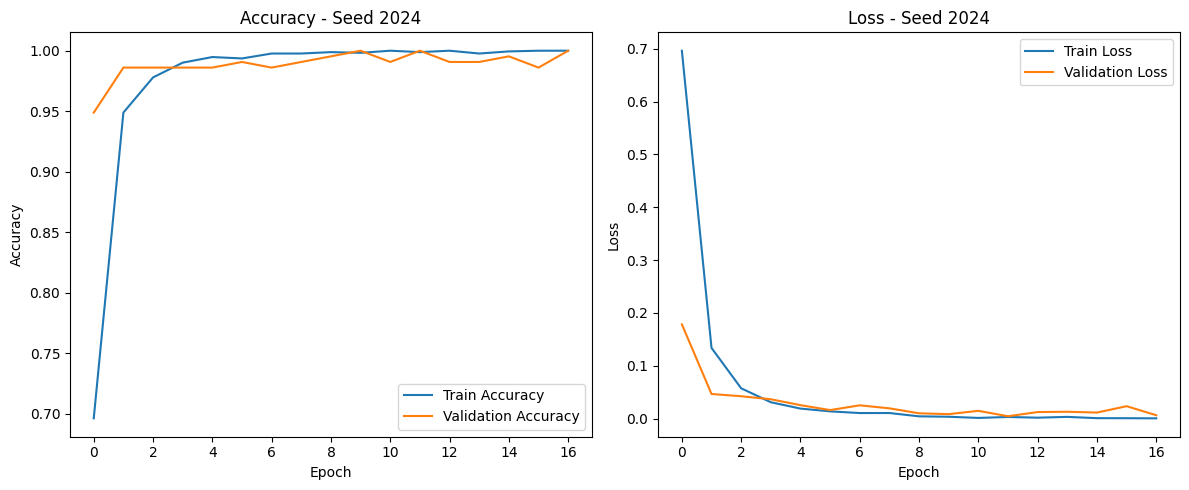


Running ResNet-50 | Seed: 3407
Train: 1721
Validation: 215
Test: 216
Class weights: {0: np.float64(0.7170833333333333), 1: np.float64(0.7170833333333333), 2: np.float64(4.741046831955923)}
Total parameters: 23,593,859
Trainable parameters: 8,925,187
Non-trainable parameters: 14,668,672
Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 339ms/step - accuracy: 0.7498 - loss: 0.8045 - val_accuracy: 0.9163 - val_loss: 0.1928
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - accuracy: 0.9504 - loss: 0.1334 - val_accuracy: 0.9581 - val_loss: 0.1243
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 125ms/step - accuracy: 0.9785 - loss: 0.0525 - val_accuracy: 0.9535 - val_loss: 0.1780
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 124ms/step - accuracy: 0.9818 - loss: 0.0349 - val_accuracy: 0.9581 - val_loss: 0.1322
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 142ms/step - accuracy: 0.9876 - loss: 0.0237 - val_accuracy: 0.9721 - val_loss: 0.0769
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 119ms/step - accuracy: 0.998

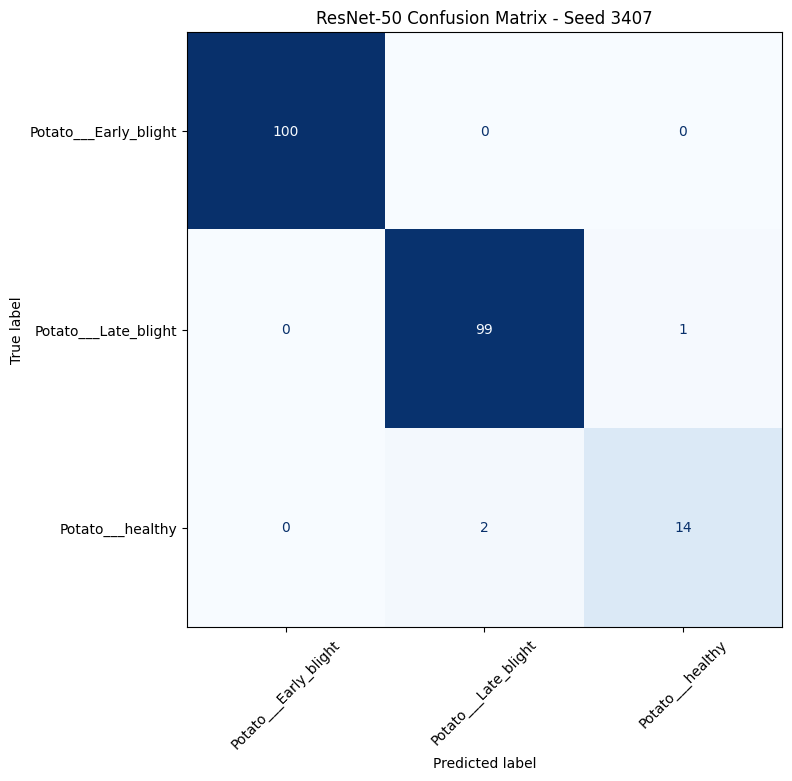

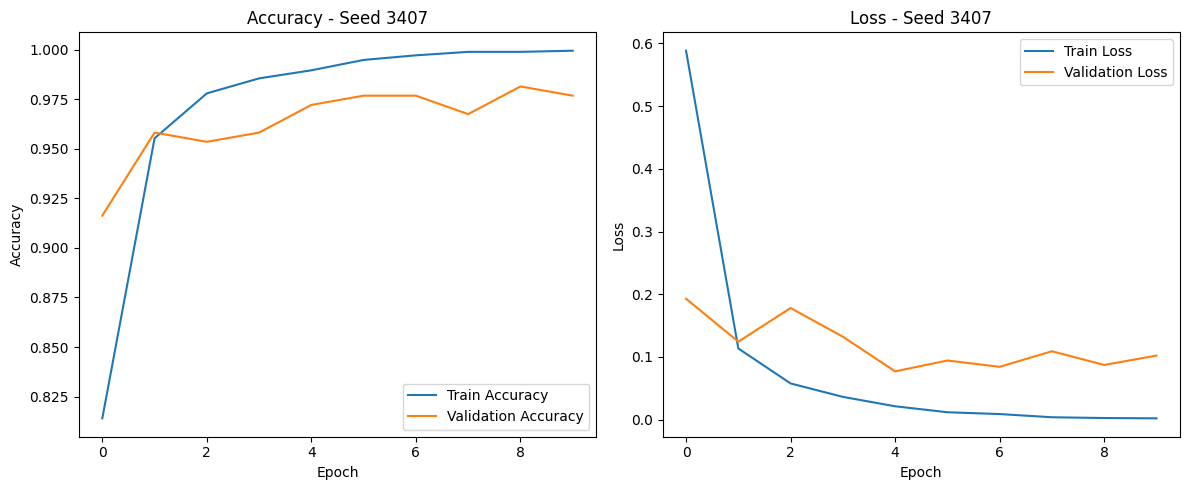


Running ResNet-50 | Seed: 777
Train: 1721
Validation: 215
Test: 216
Class weights: {0: np.float64(0.7170833333333333), 1: np.float64(0.7170833333333333), 2: np.float64(4.741046831955923)}
Total parameters: 23,593,859
Trainable parameters: 8,925,187
Non-trainable parameters: 14,668,672
Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 339ms/step - accuracy: 0.6549 - loss: 0.8925 - val_accuracy: 0.9163 - val_loss: 0.1693
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - accuracy: 0.9509 - loss: 0.1403 - val_accuracy: 0.9535 - val_loss: 0.1007
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 146ms/step - accuracy: 0.9801 - loss: 0.0525 - val_accuracy: 0.9535 - val_loss: 0.0976
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 144ms/step - accuracy: 0.9872 - loss: 0.0331 - val_accuracy: 0.9860 - val_loss: 0.0516
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 120ms/step - accuracy: 0.9925 - loss: 0.0175 - val_accuracy: 0.9767 - val_loss: 0.0841
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 120ms/step - accuracy: 0.996

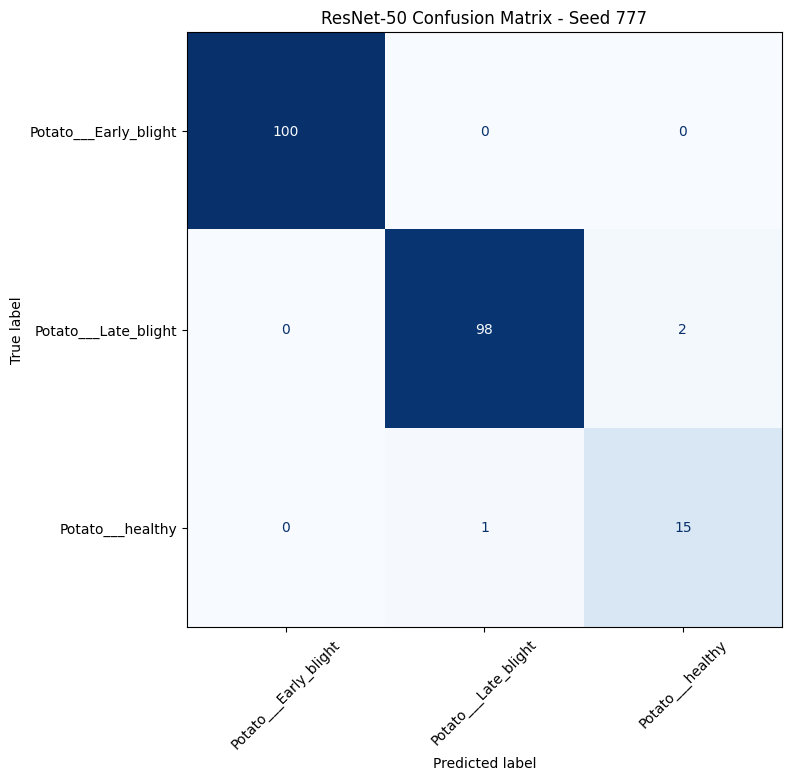

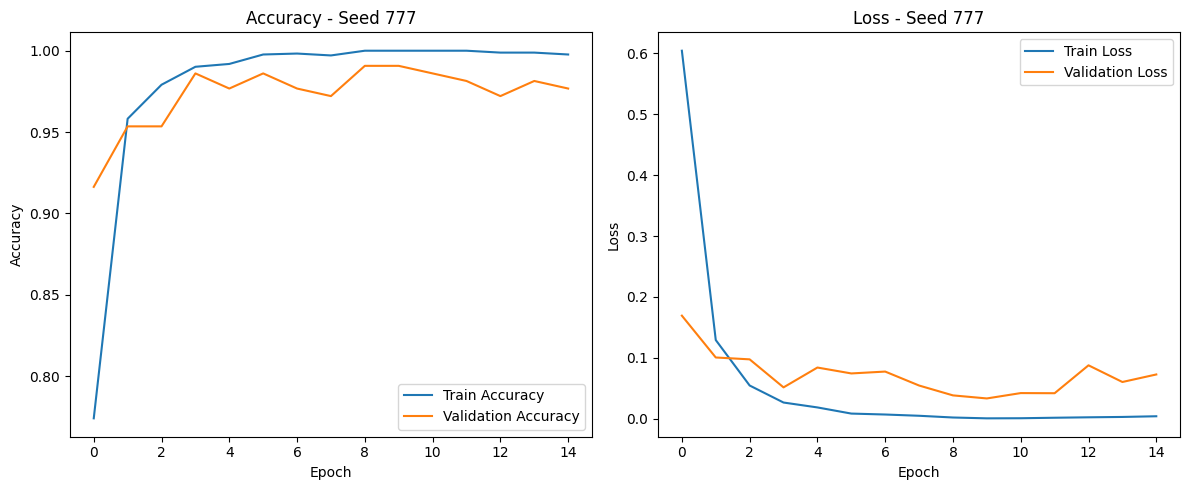


All seed results:
{'seed': 42, 'num_classes': 3, 'test_accuracy': 0.9814814925193787, 'test_loss': 0.04050523415207863, 'stopped_epoch': 11, 'best_epoch': 6, 'macro_precision': 0.9692293584100306, 'macro_recall': 0.9691666666666666, 'macro_f1': 0.9691323298996566, 'weighted_precision': 0.9815685533472648, 'weighted_recall': 0.9814814814814815, 'weighted_f1': 0.9814337915273009, 'total_params': 23593859, 'trainable_params': 8925187, 'non_trainable_params': 14668672, 'model_path': 'models/Resnet3classplantvillage_3class_seed_42.keras', 'history_path': 'history/Resnet3classplantvillage_3class_seed_42_history.pkl', 'plot_path': 'history/Resnet3classplantvillage_3class_seed_42_accuracy_loss.png', 'confusion_matrix_path': 'history/Resnet3classplantvillage_3class_seed_42_confusion_matrix.png', 'classification_report_path': 'reports/Resnet3classplantvillage_3class_seed_42_classification_report.json', 'predictions_path': 'predictions/Resnet3classplantvillage_3class_seed_42_test_predictions.csv

In [10]:
all_results = []

for seed in SEEDS:
    result = run_single_seed(seed)
    all_results.append(result)

print("\nAll seed results:")
for result in all_results:
    print(result)


In [11]:
results_df = pd.DataFrame(all_results)

csv_path = f"{EXPERIMENT_NAME}_{NUM_CLASSES}class_multiseed_results.csv"
results_df.to_csv(csv_path, index=False)

print("Saved results to:", csv_path)
results_df


Saved results to: Resnet3classplantvillage_3class_multiseed_results.csv


,seed,num_classes,test_accuracy,test_loss,stopped_epoch,best_epoch,macro_precision,macro_recall,macro_f1,weighted_precision,...,weighted_f1,total_params,trainable_params,non_trainable_params,model_path,history_path,plot_path,confusion_matrix_path,classification_report_path,predictions_path
0,42,3,0.981481,0.040505,11,6,0.969229,0.969167,0.969132,0.981569,...,0.981434,23593859,8925187,14668672,models/Resnet3classplantvillage_3class_seed_42...,history/Resnet3classplantvillage_3class_seed_4...,history/Resnet3classplantvillage_3class_seed_4...,history/Resnet3classplantvillage_3class_seed_4...,reports/Resnet3classplantvillage_3class_seed_4...,predictions/Resnet3classplantvillage_3class_se...
1,123,3,0.986111,0.066105,13,8,0.971177,0.955000,0.962767,0.985894,...,0.985922,23593859,8925187,14668672,models/Resnet3classplantvillage_3class_seed_12...,history/Resnet3classplantvillage_3class_seed_1...,history/Resnet3classplantvillage_3class_seed_1...,history/Resnet3classplantvillage_3class_seed_1...,reports/Resnet3classplantvillage_3class_seed_1...,predictions/Resnet3classplantvillage_3class_se...
2,2024,3,1.000000,0.008246,17,12,1.000000,1.000000,1.000000,1.000000,...,1.000000,23593859,8925187,14668672,models/Resnet3classplantvillage_3class_seed_20...,history/Resnet3classplantvillage_3class_seed_2...,history/Resnet3classplantvillage_3class_seed_2...,history/Resnet3classplantvillage_3class_seed_2...,reports/Resnet3classplantvillage_3class_seed_2...,predictions/Resnet3classplantvillage_3class_se...
3,3407,3,0.986111,0.049513,10,5,0.971177,0.955000,0.962767,0.985894,...,0.985922,23593859,8925187,14668672,models/Resnet3classplantvillage_3class_seed_34...,history/Resnet3classplantvillage_3class_seed_3...,history/Resnet3classplantvillage_3class_seed_3...,history/Resnet3classplantvillage_3class_seed_3...,reports/Resnet3classplantvillage_3class_seed_3...,predictions/Resnet3classplantvillage_3class_se...
4,777,3,0.986111,0.082098,15,10,0.957417,0.972500,0.964672,0.986609,...,0.986287,23593859,8925187,14668672,models/Resnet3classplantvillage_3class_seed_77...,history/Resnet3classplantvillage_3class_seed_7...,history/Resnet3classplantvillage_3class_seed_7...,history/Resnet3classplantvillage_3class_seed_7...,reports/Resnet3classplantvillage_3class_seed_7...,predictions/Resnet3classplantvillage_3class_se...


In [12]:
metrics = [
    "test_accuracy",
    "test_loss",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_precision",
    "weighted_recall",
    "weighted_f1",
    "stopped_epoch",
    "best_epoch"
]

summary_rows = []

for metric in metrics:
    values = results_df[metric].astype(float).values

    summary_rows.append({
        "metric": metric,
        "mean": np.mean(values),
        "std": np.std(values),
        "min": np.min(values),
        "max": np.max(values)
    })

summary_df = pd.DataFrame(summary_rows)

summary_csv_path = f"{EXPERIMENT_NAME}_{NUM_CLASSES}class_multiseed_summary.csv"
summary_df.to_csv(summary_csv_path, index=False)

print("Multi-seed summary report")
print("=" * 70)
display(summary_df)

print("Saved summary report to:", summary_csv_path)

print("\nPaper-style summary:")
print(f"Accuracy: {results_df['test_accuracy'].mean():.4f} ± {results_df['test_accuracy'].std(ddof=0):.4f}")
print(f"Loss: {results_df['test_loss'].mean():.4f} ± {results_df['test_loss'].std(ddof=0):.4f}")
print(f"Macro F1: {results_df['macro_f1'].mean():.4f} ± {results_df['macro_f1'].std(ddof=0):.4f}")
print(f"Weighted F1: {results_df['weighted_f1'].mean():.4f} ± {results_df['weighted_f1'].std(ddof=0):.4f}")


Multi-seed summary report


,metric,mean,std,min,max
0,test_accuracy,0.987963,0.006280,0.981481,1.000000
1,test_loss,0.049293,0.024984,0.008246,0.082098
2,macro_precision,0.973800,0.014068,0.957417,1.000000
3,macro_recall,0.970333,0.016471,0.955000,1.000000
4,macro_f1,0.971868,0.014257,0.962767,1.000000
5,weighted_precision,0.987993,0.006264,0.981569,1.000000
6,weighted_recall,0.987963,0.006280,0.981481,1.000000
7,weighted_f1,0.987913,0.006303,0.981434,1.000000
8,stopped_epoch,13.200000,2.561250,10.000000,17.000000
9,best_epoch,8.200000,2.561250,5.000000,12.000000


Saved summary report to: Resnet3classplantvillage_3class_multiseed_summary.csv

Paper-style summary:
Accuracy: 0.9880 ± 0.0063
Loss: 0.0493 ± 0.0250
Macro F1: 0.9719 ± 0.0143
Weighted F1: 0.9879 ± 0.0063


In [13]:
mean_acc = results_df["test_accuracy"].mean()

results_df["distance_from_mean_accuracy"] = (
    results_df["test_accuracy"] - mean_acc
).abs()

representative_row = results_df.sort_values("distance_from_mean_accuracy").iloc[0]

MODEL_PATH = representative_row["model_path"]
SEED_TO_ANALYZE = int(representative_row["seed"])

print("Mean accuracy:", mean_acc)
print("Representative seed:", SEED_TO_ANALYZE)
print("Representative model:", MODEL_PATH)

representative_row


Mean accuracy: 0.9879629611968994
Representative seed: 123
Representative model: models/Resnet3classplantvillage_3class_seed_123.keras


seed                                                                         123
num_classes                                                                    3
test_accuracy                                                           0.986111
test_loss                                                               0.066105
stopped_epoch                                                                 13
best_epoch                                                                     8
macro_precision                                                         0.971177
macro_recall                                                               0.955
macro_f1                                                                0.962767
weighted_precision                                                      0.985894
weighted_recall                                                         0.986111
weighted_f1                                                             0.985922
total_params                

In [14]:

# ============================================================
# ResNet-50: Load Trained Three-Class Model
# ============================================================

from tensorflow.keras.models import load_model

MODEL_TYPE = "resnet50"
IMAGE_SIZE = (224, 224)

model = load_model(
    MODEL_PATH,
    compile=False
)

print("Loaded model:", MODEL_PATH)
print("Model name:", model.name)
print("Output classes:", model.output_shape[-1])

assert model.output_shape[-1] == 3, (
    "Expected a three-class ResNet-50 model."
)


Loaded model: models/Resnet3classplantvillage_3class_seed_123.keras
Model name: ResNet50_3class_finetuned
Output classes: 3


In [15]:
X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size=0.20,
    stratify=labels,
    random_state=SEED_TO_ANALYZE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED_TO_ANALYZE
)

print("Test images:", len(X_test))


Test images: 216


In [16]:

# ============================================================
# ResNet-50: Image Loading and Test Predictions (3 Classes)
# ============================================================

def load_image_for_model(image_path):
    image_raw = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image_raw,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)

    # Preserve the original RGB image for Grad-CAM display
    original_image = tf.clip_by_value(
        image, 0.0, 255.0
    ).numpy().astype(np.uint8)

    # Uses ResNet-50 preprocessing from the imports cell
    processed_image = preprocess_input(image)
    processed_image = tf.expand_dims(
        processed_image,
        axis=0
    )

    return processed_image, original_image


# ============================================================
# Class Mapping
# ============================================================

idx_to_class = {
    i: name for i, name in enumerate(class_names)
}

class_to_idx = {
    name: i for i, name in enumerate(class_names)
}


# ============================================================
# Generate Predictions for the Selected Test Split
# ============================================================

records = []

for image_path, true_label in zip(X_test, y_test):

    processed_image, _ = load_image_for_model(image_path)

    probs = model.predict(
        processed_image,
        verbose=0
    )[0]

    pred_label = int(np.argmax(probs))
    confidence = float(np.max(probs))

    record = {
        "image_path": image_path,
        "true_label": int(true_label),
        "true_class": idx_to_class[int(true_label)],
        "predicted_label": pred_label,
        "pred_class": idx_to_class[pred_label],
        "confidence": confidence,
        "correct": int(true_label) == pred_label
    }

    # Save probability for every class
    for class_idx in range(NUM_CLASSES):
        record[f"prob_class_{class_idx}"] = float(
            probs[class_idx]
        )

    records.append(record)


# ============================================================
# Save Predictions
# ============================================================

pred_df = pd.DataFrame(records)

pred_csv_path = (
    f"test_predictions_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

pred_df.to_csv(
    pred_csv_path,
    index=False
)

print("Saved predictions to:", pred_csv_path)
print("Total test images:", len(pred_df))
print("Test accuracy:", round(pred_df["correct"].mean() * 100, 2), "%")

display(pred_df.head())


Saved predictions to: test_predictions_resnet50_3class_seed_123.csv
Total test images: 216
Test accuracy: 98.61 %


,image_path,true_label,true_class,predicted_label,pred_class,confidence,correct,prob_class_0,prob_class_1,prob_class_2
0,/kaggle/input/datasets/faysalmiah1721758/potat...,0,Potato___Early_blight,0,Potato___Early_blight,1.000000,True,1.000000e+00,9.920042e-12,1.076907e-15
1,/kaggle/input/datasets/faysalmiah1721758/potat...,0,Potato___Early_blight,0,Potato___Early_blight,0.999996,True,9.999964e-01,2.082047e-06,1.511465e-06
2,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,0.999995,True,4.613104e-06,9.999954e-01,2.947401e-08
3,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,0.999999,True,7.270689e-09,9.999994e-01,6.334716e-07
4,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,0.977763,True,2.223732e-02,9.777626e-01,2.639760e-10


In [17]:

# ============================================================
# ResNet-50: Three-Way Decision Assignment (3 Classes)
# ============================================================

ALPHA = 0.90
BETA = 0.60

assert 0.0 <= BETA < ALPHA <= 1.0

def assign_three_way_region(confidence):
    if confidence >= ALPHA:
        return "Accept"
    elif confidence >= BETA:
        return "Defer"
    else:
        return "Reject"


twd_df = pred_df.copy()

twd_df["decision_region"] = (
    twd_df["confidence"].apply(assign_three_way_region)
)

print("Three-way decision thresholds:")
print(f"Accept: confidence >= {ALPHA}")
print(f"Defer:  {BETA} <= confidence < {ALPHA}")
print(f"Reject: confidence < {BETA}")

display(twd_df.head())


Three-way decision thresholds:
Accept: confidence >= 0.9
Defer:  0.6 <= confidence < 0.9
Reject: confidence < 0.6


,image_path,true_label,true_class,predicted_label,pred_class,confidence,correct,prob_class_0,prob_class_1,prob_class_2,decision_region
0,/kaggle/input/datasets/faysalmiah1721758/potat...,0,Potato___Early_blight,0,Potato___Early_blight,1.000000,True,1.000000e+00,9.920042e-12,1.076907e-15,Accept
1,/kaggle/input/datasets/faysalmiah1721758/potat...,0,Potato___Early_blight,0,Potato___Early_blight,0.999996,True,9.999964e-01,2.082047e-06,1.511465e-06,Accept
2,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,0.999995,True,4.613104e-06,9.999954e-01,2.947401e-08,Accept
3,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,0.999999,True,7.270689e-09,9.999994e-01,6.334716e-07,Accept
4,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,0.977763,True,2.223732e-02,9.777626e-01,2.639760e-10,Accept


In [18]:

# ============================================================
# ResNet-50: Three-Way Decision Performance (3 Classes)
# ============================================================

total_samples = len(twd_df)
assert total_samples > 0, "No test predictions found."

regions = ["Accept", "Defer", "Reject"]

# ------------------------------------------------------------
# Region counts and percentages
# ------------------------------------------------------------
region_counts = (
    twd_df["decision_region"]
    .value_counts()
    .reindex(regions, fill_value=0)
)

region_percentages = (
    region_counts / total_samples
) * 100

print("Three-way decision counts:")

for region in regions:
    print(
        f"{region}: {region_counts[region]} samples "
        f"({region_percentages[region]:.2f}%)"
    )

# ------------------------------------------------------------
# Overall test performance
# ------------------------------------------------------------
overall_accuracy = twd_df["correct"].mean()
overall_error_rate = 1.0 - overall_accuracy

# ------------------------------------------------------------
# Accept region performance
# ------------------------------------------------------------
accept_df = twd_df[
    twd_df["decision_region"] == "Accept"
]

accept_coverage = len(accept_df) / total_samples

if len(accept_df) > 0:
    accept_accuracy = accept_df["correct"].mean()
    accept_error_rate = 1.0 - accept_accuracy
else:
    accept_accuracy = np.nan
    accept_error_rate = np.nan

# ------------------------------------------------------------
# Wrong prediction capture
# ------------------------------------------------------------
wrong_df = twd_df[
    twd_df["correct"] == False
]

wrong_captured_df = wrong_df[
    wrong_df["decision_region"].isin(
        ["Defer", "Reject"]
    )
]

num_wrong_total = len(wrong_df)
num_wrong_captured = len(wrong_captured_df)

if num_wrong_total > 0:
    wrong_capture_rate = (
        num_wrong_captured / num_wrong_total
    )
else:
    wrong_capture_rate = np.nan

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------
print("\nOverall test performance:")
print(f"Accuracy: {overall_accuracy:.4f}")
print(f"Error rate: {overall_error_rate:.4f}")

print("\nAccept region:")
print(f"Accept coverage: {accept_coverage:.4f}")
print(f"Accept accuracy: {accept_accuracy:.4f}")
print(f"Accept error rate: {accept_error_rate:.4f}")

print("\nWrong prediction analysis:")
print(f"Total wrong predictions: {num_wrong_total}")
print(
    "Wrong predictions captured by Defer/Reject:",
    num_wrong_captured
)
print(f"Wrong capture rate: {wrong_capture_rate:.4f}")

# ------------------------------------------------------------
# Region-wise accuracy
# ------------------------------------------------------------
print("\nRegion-wise accuracy:")

for region in regions:
    region_df = twd_df[
        twd_df["decision_region"] == region
    ]

    if len(region_df) > 0:
        accuracy = region_df["correct"].mean()
        print(
            f"{region}: {accuracy:.4f} "
            f"(n={len(region_df)})"
        )
    else:
        print(f"{region}: N/A (n=0)")


Three-way decision counts:
Accept: 213 samples (98.61%)
Defer: 2 samples (0.93%)
Reject: 1 samples (0.46%)

Overall test performance:
Accuracy: 0.9861
Error rate: 0.0139

Accept region:
Accept coverage: 0.9861
Accept accuracy: 0.9859
Accept error rate: 0.0141

Wrong prediction analysis:
Total wrong predictions: 3
Wrong predictions captured by Defer/Reject: 0
Wrong capture rate: 0.0000

Region-wise accuracy:
Accept: 0.9859 (n=213)
Defer: 1.0000 (n=2)
Reject: 1.0000 (n=1)


In [19]:
class_region_counts = pd.crosstab(
    twd_df["true_class"],
    twd_df["decision_region"]
).reindex(columns=["Accept", "Defer", "Reject"], fill_value=0)

class_region_percentages = class_region_counts.div(
    class_region_counts.sum(axis=1),
    axis=0
) * 100

print("Class-wise Accept / Defer / Reject counts:")
display(class_region_counts)

print("Class-wise Accept / Defer / Reject percentages:")
display(class_region_percentages.round(2))


Class-wise Accept / Defer / Reject counts:


decision_region,Accept,Defer,Reject
true_class,,,
Potato___Early_blight,99,0,1
Potato___Late_blight,99,1,0
Potato___healthy,15,1,0


Class-wise Accept / Defer / Reject percentages:


decision_region,Accept,Defer,Reject
true_class,,,
Potato___Early_blight,99.00,0.00,1.0
Potato___Late_blight,99.00,1.00,0.0
Potato___healthy,93.75,6.25,0.0


In [20]:

# ============================================================
# ResNet-50: Save Three-Way Decision Results (3 Classes)
# ============================================================

# Save individual test predictions and decision regions
three_way_csv = (
    f"three_way_decision_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

twd_df.to_csv(three_way_csv, index=False)

# Save summary statistics
summary = {
    "seed": SEED_TO_ANALYZE,
    "model": MODEL_TYPE,
    "num_classes": NUM_CLASSES,
    "alpha": ALPHA,
    "beta": BETA,
    "total_samples": total_samples,

    "overall_accuracy": float(overall_accuracy),
    "overall_error_rate": float(overall_error_rate),

    "accept_count": int(region_counts["Accept"]),
    "defer_count": int(region_counts["Defer"]),
    "reject_count": int(region_counts["Reject"]),

    "accept_percentage": float(region_percentages["Accept"]),
    "defer_percentage": float(region_percentages["Defer"]),
    "reject_percentage": float(region_percentages["Reject"]),

    "accept_coverage": float(accept_coverage),
    "accept_accuracy": float(accept_accuracy),
    "accept_error_rate": float(accept_error_rate),

    "total_wrong_predictions": int(num_wrong_total),
    "wrong_predictions_captured_by_defer_reject": int(num_wrong_captured),
    "wrong_capture_rate": float(wrong_capture_rate)
}

summary_df = pd.DataFrame([summary])

summary_csv = (
    f"three_way_decision_summary_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

summary_df.to_csv(summary_csv, index=False)

# Save class-wise results
class_counts_csv = (
    f"three_way_class_counts_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

class_percentages_csv = (
    f"three_way_class_percentages_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

class_region_counts.to_csv(class_counts_csv)
class_region_percentages.to_csv(class_percentages_csv)

print("Saved:", three_way_csv)
print("Saved:", summary_csv)
print("Saved:", class_counts_csv)
print("Saved:", class_percentages_csv)

display(summary_df)


Saved: three_way_decision_resnet50_3class_seed_123.csv
Saved: three_way_decision_summary_resnet50_3class_seed_123.csv
Saved: three_way_class_counts_resnet50_3class_seed_123.csv
Saved: three_way_class_percentages_resnet50_3class_seed_123.csv


,seed,model,num_classes,alpha,beta,total_samples,overall_accuracy,overall_error_rate,accept_count,defer_count,reject_count,accept_percentage,defer_percentage,reject_percentage,accept_coverage,accept_accuracy,accept_error_rate,total_wrong_predictions,wrong_predictions_captured_by_defer_reject,wrong_capture_rate
0,123,resnet50,3,0.9,0.6,216,0.986111,0.013889,213,2,1,98.611111,0.925926,0.462963,0.986111,0.985915,0.014085,3,0,0.0


In [ ]:
three_way_csv = f"three_way_decision_{MODEL_TYPE}_{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
twd_df.to_csv(three_way_csv, index=False)

summary = {
    "total_samples": total_samples,
    "accept_count": int(region_counts["Accept"]),
    "defer_count": int(region_counts["Defer"]),
    "reject_count": int(region_counts["Reject"]),
    "accept_percentage": float(region_percentages["Accept"]),
    "defer_percentage": float(region_percentages["Defer"]),
    "reject_percentage": float(region_percentages["Reject"]),
    "accept_accuracy": float(accept_accuracy),
    "accept_error_rate": float(accept_error_rate),
    "total_wrong_predictions": int(num_wrong_total),
    "wrong_predictions_captured_by_defer_reject": int(num_wrong_captured),
    "wrong_capture_rate": float(wrong_capture_rate)
}

summary_df = pd.DataFrame([summary])

summary_csv = f"three_way_decision_summary_{MODEL_TYPE}_{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
summary_df.to_csv(summary_csv, index=False)

print("Saved:", three_way_csv)
print("Saved:", summary_csv)

summary_df


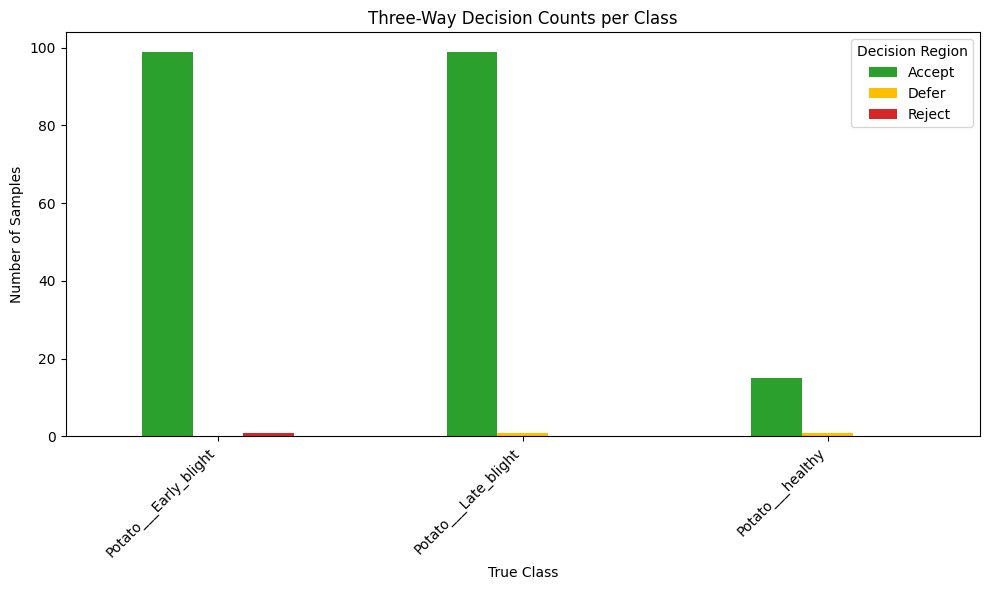

Saved: three_way_decision_counts_resnet50_3class_seed_123.png


In [21]:
ax = class_region_counts.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#2ca02c", "#ffbf00", "#d62728"]
)

ax.set_title("Three-Way Decision Counts per Class")
ax.set_xlabel("True Class")
ax.set_ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Decision Region")
plt.tight_layout()

three_way_plot = f"three_way_decision_counts_{MODEL_TYPE}_{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.png"
plt.savefig(three_way_plot, dpi=300)
plt.show()

print("Saved:", three_way_plot)


In [22]:
SAMPLES_PER_GROUP = 3

OUTPUT_DIR = f"gradcam_{MODEL_TYPE}_{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Grad-CAM output folder:", OUTPUT_DIR)
print("Class names:", class_names)


Grad-CAM output folder: gradcam_resnet50_3class_seed_123
Class names: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [23]:

# ============================================================
# ResNet-50: Select Grad-CAM Samples (3 Classes)
# ============================================================

analysis_groups = {
    "correct_early_blight": {
        "true": "Potato___Early_blight",
        "pred": "Potato___Early_blight"
    },
    "correct_late_blight": {
        "true": "Potato___Late_blight",
        "pred": "Potato___Late_blight"
    },
    "correct_healthy": {
        "true": "Potato___healthy",
        "pred": "Potato___healthy"
    },
    "early_blight_as_late_blight": {
        "true": "Potato___Early_blight",
        "pred": "Potato___Late_blight"
    },
    "late_blight_as_early_blight": {
        "true": "Potato___Late_blight",
        "pred": "Potato___Early_blight"
    },
    "healthy_as_early_blight": {
        "true": "Potato___healthy",
        "pred": "Potato___Early_blight"
    },
    "healthy_as_late_blight": {
        "true": "Potato___healthy",
        "pred": "Potato___Late_blight"
    }
}

selected_samples = []

for group_name, rule in analysis_groups.items():

    group_df = pred_df[
        (pred_df["true_class"] == rule["true"]) &
        (pred_df["pred_class"] == rule["pred"])
    ].copy()

    group_df["decision_region"] = (
        group_df["confidence"].apply(assign_three_way_region)
    )

    group_df = group_df.sort_values(
        ["confidence", "image_path"],
        ascending=[False, True]
    )

    selected_indices = []

    # Select one sample from each available decision region
    for region in ["Accept", "Defer", "Reject"]:

        region_df = group_df[
            group_df["decision_region"] == region
        ]

        if not region_df.empty:
            selected_indices.append(region_df.index[0])

        if len(selected_indices) >= SAMPLES_PER_GROUP:
            break

    # Fill remaining slots with highest-confidence samples
    if len(selected_indices) < SAMPLES_PER_GROUP:

        remaining_df = group_df.drop(
            index=selected_indices
        )

        slots = SAMPLES_PER_GROUP - len(selected_indices)

        selected_indices.extend(
            remaining_df.head(slots).index.tolist()
        )

    selected_group_df = group_df.loc[selected_indices]

    print(
        f"{group_name}: selected "
        f"{len(selected_group_df)} samples"
    )

    for _, row in selected_group_df.iterrows():
        sample = row.to_dict()
        sample["group"] = group_name
        selected_samples.append(sample)


# ============================================================
# Save Selected Samples
# ============================================================

selected_df = pd.DataFrame(selected_samples)

selected_csv_path = os.path.join(
    OUTPUT_DIR,
    "selected_gradcam_samples.csv"
)

selected_df.to_csv(
    selected_csv_path,
    index=False
)

print("\nSaved selected samples to:", selected_csv_path)
print("Total selected samples:", len(selected_df))

display(selected_df)


correct_early_blight: selected 3 samples
correct_late_blight: selected 3 samples
correct_healthy: selected 3 samples
early_blight_as_late_blight: selected 0 samples
late_blight_as_early_blight: selected 0 samples
healthy_as_early_blight: selected 0 samples
healthy_as_late_blight: selected 2 samples

Saved selected samples to: gradcam_resnet50_3class_seed_123/selected_gradcam_samples.csv
Total selected samples: 11


,image_path,true_label,true_class,predicted_label,pred_class,confidence,correct,prob_class_0,prob_class_1,prob_class_2,decision_region,group
0,/kaggle/input/datasets/faysalmiah1721758/potat...,0,Potato___Early_blight,0,Potato___Early_blight,1.000000,True,1.000000e+00,1.649286e-09,2.629100e-13,Accept,correct_early_blight
1,/kaggle/input/datasets/faysalmiah1721758/potat...,0,Potato___Early_blight,0,Potato___Early_blight,0.590521,True,5.905214e-01,4.094776e-01,9.635827e-07,Reject,correct_early_blight
2,/kaggle/input/datasets/faysalmiah1721758/potat...,0,Potato___Early_blight,0,Potato___Early_blight,1.000000,True,1.000000e+00,1.178225e-08,3.038654e-10,Accept,correct_early_blight
3,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,1.000000,True,5.152659e-08,1.000000e+00,9.778489e-09,Accept,correct_late_blight
4,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,0.893303,True,3.651587e-06,8.933031e-01,1.066933e-01,Defer,correct_late_blight
5,/kaggle/input/datasets/faysalmiah1721758/potat...,1,Potato___Late_blight,1,Potato___Late_blight,1.000000,True,6.099700e-14,1.000000e+00,2.280576e-12,Accept,correct_late_blight
6,/kaggle/input/datasets/faysalmiah1721758/potat...,2,Potato___healthy,2,Potato___healthy,0.999994,True,4.630508e-07,5.987499e-06,9.999936e-01,Accept,correct_healthy
7,/kaggle/input/datasets/faysalmiah1721758/potat...,2,Potato___healthy,2,Potato___healthy,0.624234,True,3.034921e-08,3.757656e-01,6.242344e-01,Defer,correct_healthy
8,/kaggle/input/datasets/faysalmiah1721758/potat...,2,Potato___healthy,2,Potato___healthy,0.999988,True,1.620475e-06,1.057253e-05,9.999878e-01,Accept,correct_healthy
9,/kaggle/input/datasets/faysalmiah1721758/potat...,2,Potato___healthy,1,Potato___Late_blight,0.983128,False,3.823532e-04,9.831277e-01,1.649004e-02,Accept,healthy_as_late_blight


In [24]:

# ============================================================
# ResNet-50: Configure Grad-CAM Target Layer (3 Classes)
# ============================================================

LAST_CONV_LAYER_NAME = "conv5_block3_out"

# Confirm the target layer exists
target_layer = model.get_layer(LAST_CONV_LAYER_NAME)

print("Grad-CAM target layer:", target_layer.name)
print("Target layer output shape:", target_layer.output.shape)

# Verify the trained model is callable
dummy_input = tf.zeros(
    (1, IMAGE_SIZE[0], IMAGE_SIZE[1], 3),
    dtype=tf.float32
)

_ = model(dummy_input, training=False)

# Create model returning both spatial features and predictions
gradcam_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        target_layer.output,
        model.outputs[0]
    ]
)

print("Grad-CAM model created successfully.")
print("Grad-CAM target:", LAST_CONV_LAYER_NAME)


Grad-CAM target layer: conv5_block3_out
Target layer output shape: (None, 7, 7, 2048)
Grad-CAM model created successfully.
Grad-CAM target: conv5_block3_out


In [25]:

# ============================================================
# ResNet-50: Grad-CAM Heatmap Generation (3 Classes)
# ============================================================

def make_gradcam_heatmap(
    processed_image,
    gradcam_model,
    class_index=None
):
    with tf.GradientTape() as tape:
        conv_outputs, predictions = gradcam_model(
            processed_image,
            training=False
        )

        if class_index is None:
            class_index = tf.argmax(
                predictions[0],
                output_type=tf.int32
            )

        class_index = tf.cast(class_index, tf.int32)

        # Corrected gradient target
        # Do not add [:, 0] after tf.gather.
        class_score = tf.gather(
            predictions,
            class_index,
            axis=1
        )

    grads = tape.gradient(
        class_score,
        conv_outputs
    )

    if grads is None:
        raise ValueError(
            "Gradients are None. Grad-CAM graph is disconnected."
        )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0.0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()


# ============================================================
# Overlay Grad-CAM on Original Image
# ============================================================

def overlay_heatmap(
    original_image,
    heatmap,
    alpha=0.4,
    cmap="jet"
):
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (
            original_image.shape[0],
            original_image.shape[1]
        )
    ).numpy().squeeze()

    colormap = plt.get_cmap(cmap)

    colored_heatmap = (
        colormap(heatmap_resized)[:, :, :3]
    )

    colored_heatmap = np.uint8(
        255 * colored_heatmap
    )

    overlay = (
        alpha * colored_heatmap.astype(np.float32)
        + (1 - alpha) * original_image.astype(np.float32)
    )

    overlay = np.clip(
        overlay, 0, 255
    ).astype(np.uint8)

    return overlay


# ============================================================
# Generate and Save Grad-CAM Figure
# ============================================================

def save_gradcam_figure(sample):

    image_path = sample["image_path"]
    true_class = sample["true_class"]
    pred_class = sample["pred_class"]
    confidence = float(sample["confidence"])
    group = sample["group"]

    decision_region = sample.get(
        "decision_region",
        assign_three_way_region(confidence)
    )

    processed_image, original_image = (
        load_image_for_model(image_path)
    )

    pred_index = class_to_idx[pred_class]

    heatmap = make_gradcam_heatmap(
        processed_image=processed_image,
        gradcam_model=gradcam_model,
        class_index=pred_index
    )

    overlay = overlay_heatmap(
        original_image,
        heatmap,
        alpha=0.4
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 5)
    )

    axes[0].imshow(original_image)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(overlay)
    axes[1].set_title("Grad-CAM Overlay")
    axes[1].axis("off")

    title = (
        f"Group: {group}\n"
        f"True: {true_class} | "
        f"Predicted: {pred_class}\n"
        f"Confidence: {confidence:.4f} | "
        f"Decision: {decision_region}"
    )

    fig.suptitle(
        title,
        fontsize=11
    )

    plt.tight_layout()

    # Unique filename based on image path
    import hashlib

    image_id = hashlib.sha256(
        str(image_path).encode("utf-8")
    ).hexdigest()[:12]

    safe_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    save_path = os.path.join(
        OUTPUT_DIR,
        f"{group}_{safe_name}_{image_id}_gradcam.png"
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return save_path


Total selected samples: 11
Starting Grad-CAM generation...



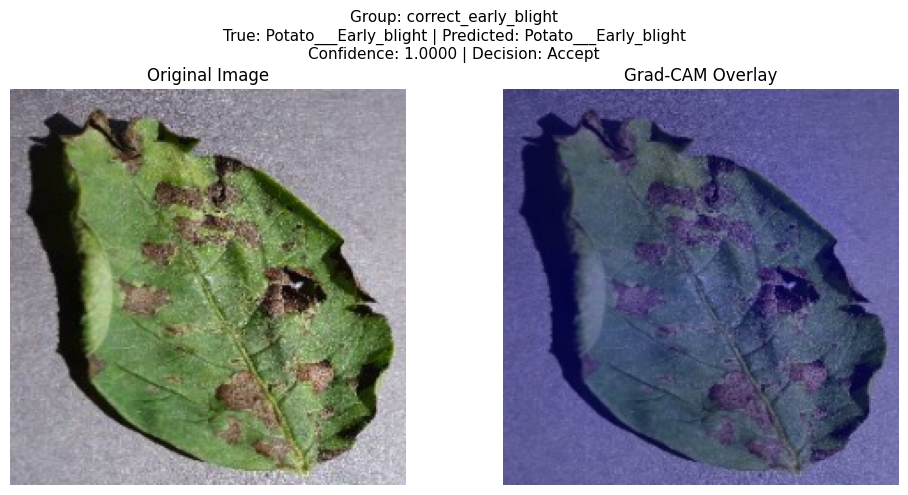

Saved 1: correct_early_blight_107827b3-faa5-457c-97fd-3e34d2657f6b___RS_Early.B 7162_4cf33aaad267_gradcam.png


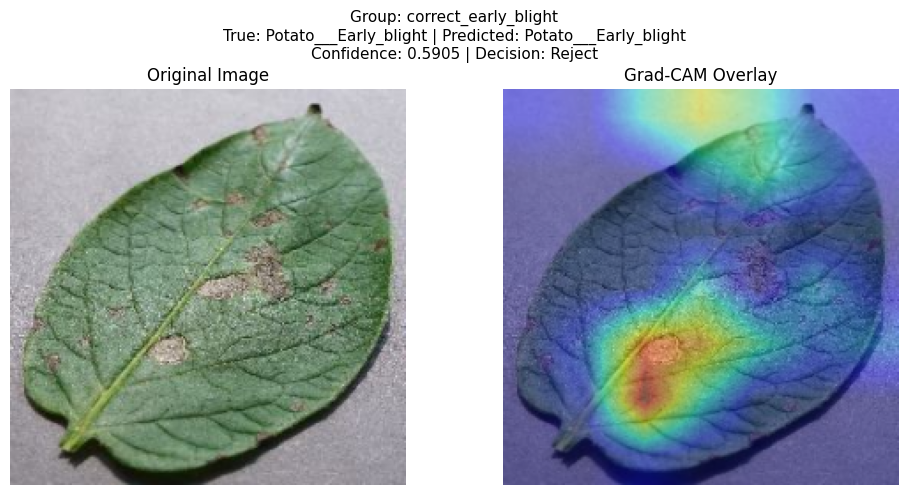

Saved 2: correct_early_blight_a0d8a499-e9e4-4c88-829c-7c2270073735___RS_Early.B 8525_32db137e9178_gradcam.png


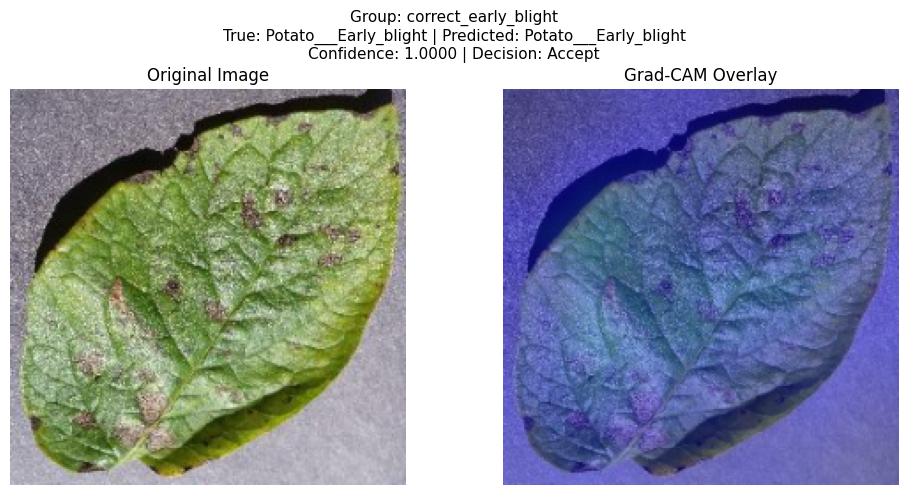

Saved 3: correct_early_blight_1a38f06b-da2a-4c57-bef1-a73254896403___RS_Early.B 9178_bbdfbdbdb911_gradcam.png


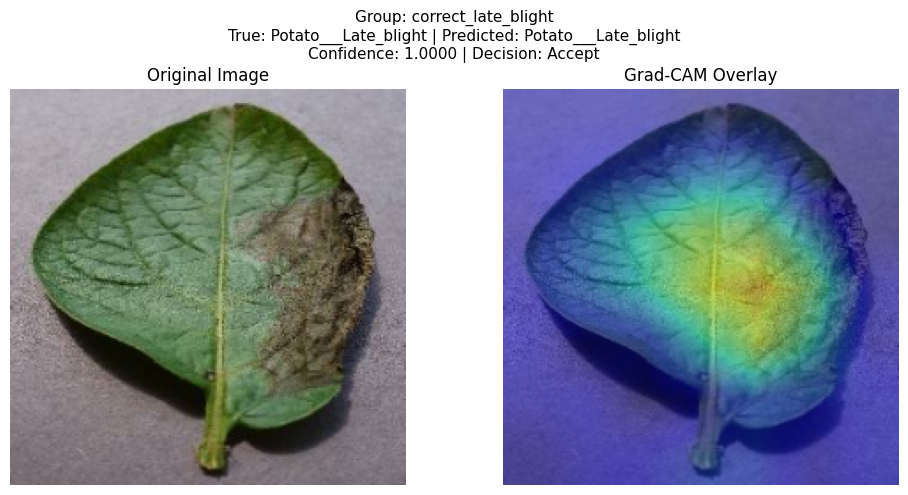

Saved 4: correct_late_blight_01a8cc9f-074a-4866-87c8-bb5a9e3895b4___RS_LB 2968_d77bbe843054_gradcam.png


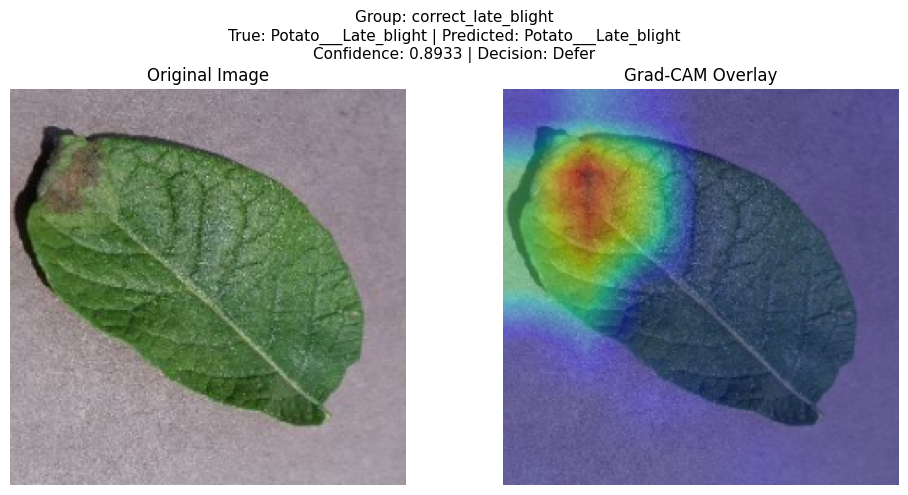

Saved 5: correct_late_blight_af17b876-b0e7-43ce-95e8-8591066dfdc9___RS_LB 3976_c6edce122472_gradcam.png


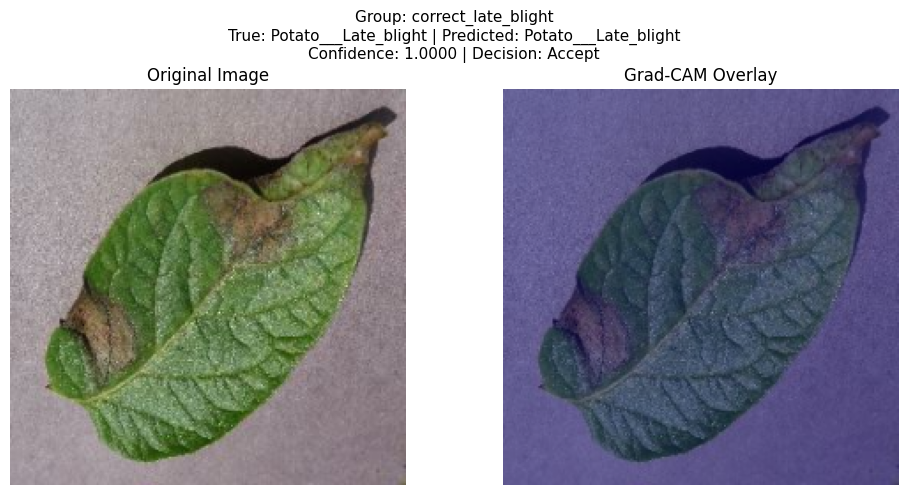

Saved 6: correct_late_blight_05817623-2c4e-4517-88a1-fe81b9a73742___RS_LB 3920_da40705d8b47_gradcam.png


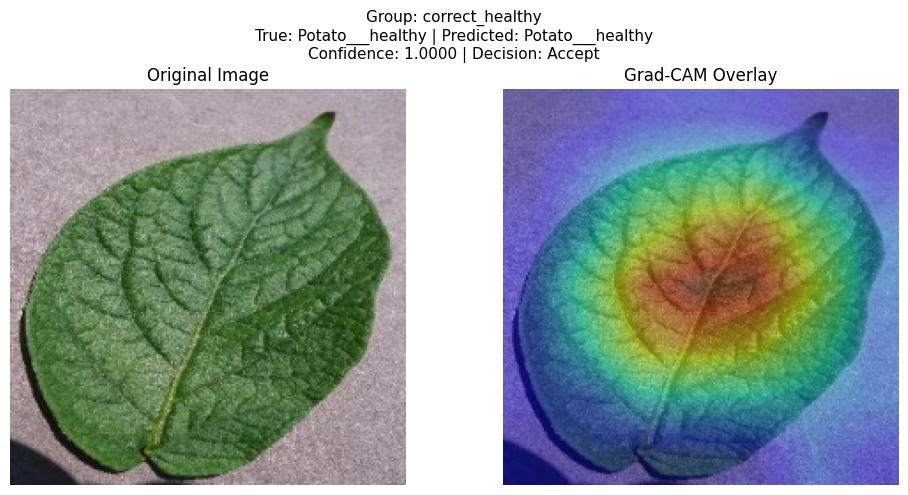

Saved 7: correct_healthy_43fd6ace-3712-494a-9aba-de5482d22561___RS_HL 1968_2b77a772da28_gradcam.png


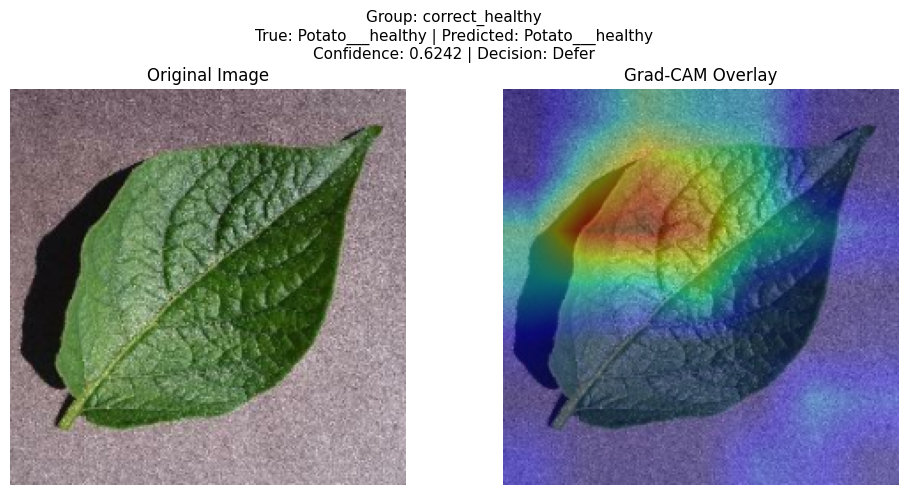

Saved 8: correct_healthy_4bbccfb6-5720-4c80-9b37-0c3ed8999c9f___RS_HL 1791_f4027a040aa9_gradcam.png


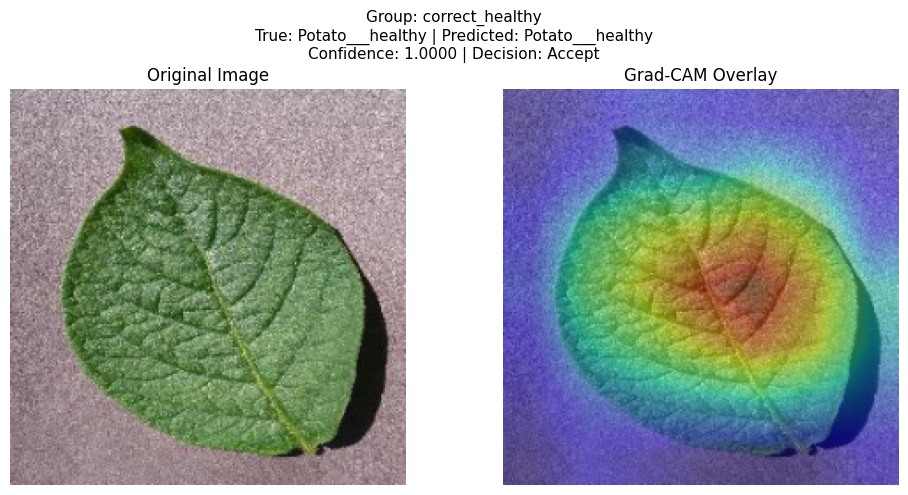

Saved 9: correct_healthy_30937333-8898-4634-8c00-af57d3020ba6___RS_HL 1922_18673d992144_gradcam.png


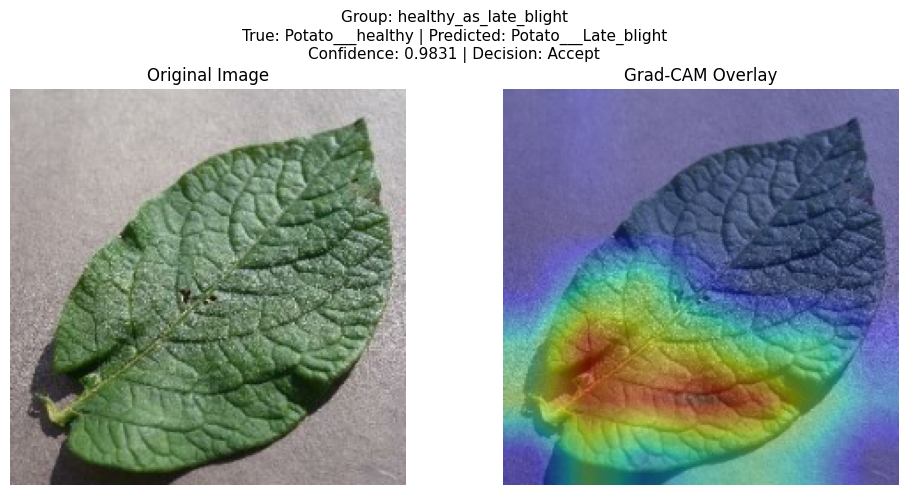

Saved 10: healthy_as_late_blight_a3ec91aa-8503-4711-a912-0d1427e25686___RS_HL 5409_f5ca62aec6cb_gradcam.png


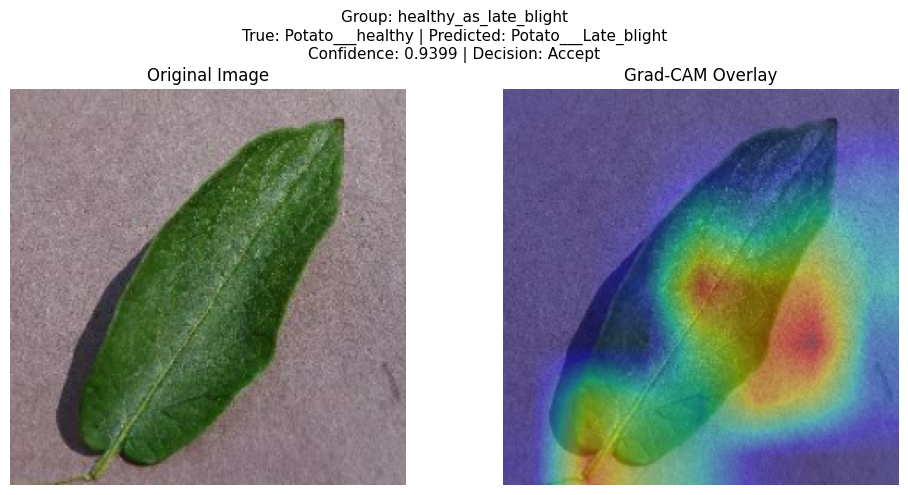

Saved 11: healthy_as_late_blight_14484ea5-9c34-427c-abe4-2743265aced0___RS_HL 4204_947b20145398_gradcam.png

ResNet-50 Grad-CAM Generation Summary
Selected samples: 11
Successfully saved: 11
Failed samples: 0
Output directory: gradcam_resnet50_3class_seed_123

All selected Grad-CAM figures saved successfully.

Saved Grad-CAM figures:
gradcam_resnet50_3class_seed_123/correct_early_blight_107827b3-faa5-457c-97fd-3e34d2657f6b___RS_Early.B 7162_4cf33aaad267_gradcam.png
gradcam_resnet50_3class_seed_123/correct_early_blight_a0d8a499-e9e4-4c88-829c-7c2270073735___RS_Early.B 8525_32db137e9178_gradcam.png
gradcam_resnet50_3class_seed_123/correct_early_blight_1a38f06b-da2a-4c57-bef1-a73254896403___RS_Early.B 9178_bbdfbdbdb911_gradcam.png
gradcam_resnet50_3class_seed_123/correct_late_blight_01a8cc9f-074a-4866-87c8-bb5a9e3895b4___RS_LB 2968_d77bbe843054_gradcam.png
gradcam_resnet50_3class_seed_123/correct_late_blight_af17b876-b0e7-43ce-95e8-8591066dfdc9___RS_LB 3976_c6edce122472_gradcam.png
gradca

In [26]:

# ============================================================
# ResNet-50: Generate and Save All Grad-CAM Figures (3 Classes)
# ============================================================

saved_gradcam_paths = []
failed_gradcam_samples = []

assert not selected_df.empty, "No Grad-CAM samples selected."

print("Total selected samples:", len(selected_df))
print("Starting Grad-CAM generation...\n")

for index, sample in selected_df.iterrows():
    try:
        save_path = save_gradcam_figure(sample)

        assert os.path.isfile(save_path), (
            f"Grad-CAM figure was not saved: {save_path}"
        )

        saved_gradcam_paths.append(save_path)

        print(
            f"Saved {len(saved_gradcam_paths)}: "
            f"{os.path.basename(save_path)}"
        )

    except Exception as e:
        failed_gradcam_samples.append({
            "image_path": sample["image_path"],
            "group": sample["group"],
            "error": str(e)
        })

        print(
            f"FAILED: {sample['image_path']} | {e}"
        )

# ============================================================
# Final Summary
# ============================================================

print("\n" + "=" * 70)
print("ResNet-50 Grad-CAM Generation Summary")
print("=" * 70)

print("Selected samples:", len(selected_df))
print("Successfully saved:", len(saved_gradcam_paths))
print("Failed samples:", len(failed_gradcam_samples))
print("Output directory:", OUTPUT_DIR)

if failed_gradcam_samples:
    failed_df = pd.DataFrame(failed_gradcam_samples)

    failed_csv = os.path.join(
        OUTPUT_DIR,
        "failed_gradcam_samples.csv"
    )

    failed_df.to_csv(failed_csv, index=False)
    print("Failure report saved:", failed_csv)

else:
    print("\nAll selected Grad-CAM figures saved successfully.")

print("\nSaved Grad-CAM figures:")
for path in saved_gradcam_paths:
    print(path)


In [27]:

# ============================================================
# ResNet-50: Export All Three-Class Experiment Outputs
# ============================================================

import os
import zipfile

PROJECT_EXPORT_NAME = "ICDM_3class_resnet50_outputs"

export_items = [
    "models",
    "history",
    "reports",
    "predictions",
    OUTPUT_DIR
]

# Include CSV and PNG files saved in the working directory
export_items.extend([
    filename
    for filename in os.listdir(".")
    if os.path.isfile(filename)
    and filename.lower().endswith((".csv", ".png"))
])

zip_path = f"{PROJECT_EXPORT_NAME}.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as zipf:

    for item in export_items:

        if os.path.isfile(item):
            zipf.write(item)

        elif os.path.isdir(item):
            for root, dirs, files in os.walk(item):
                for filename in files:
                    file_path = os.path.join(root, filename)
                    zipf.write(file_path)

print("=" * 70)
print("ResNet-50 Three-Class Export Completed")
print("=" * 70)

print("Created:", zip_path)
print("Archive size (MB):", round(
    os.path.getsize(zip_path) / (1024 ** 2), 2
))

with zipfile.ZipFile(zip_path, "r") as zipf:
    archived_files = zipf.namelist()

    print("Total archived files:", len(archived_files))

    bad_file = zipf.testzip()
    print(
        "Archive integrity:",
        "PASS" if bad_file is None else f"FAILED: {bad_file}"
    )

    print("\nSaved model checkpoints:")
    for filename in archived_files:
        if filename.startswith("models/") and filename.endswith(".keras"):
            print(filename)

print("\nDownload this ZIP from Kaggle Output.")


ResNet-50 Three-Class Export Completed
Created: ICDM_3class_resnet50_outputs.zip
Archive size (MB): 744.18
Total archived files: 50
Archive integrity: PASS

Saved model checkpoints:
models/Resnet3classplantvillage_3class_seed_2024.keras
models/Resnet3classplantvillage_3class_seed_42.keras
models/Resnet3classplantvillage_3class_seed_123.keras
models/Resnet3classplantvillage_3class_seed_3407.keras
models/Resnet3classplantvillage_3class_seed_777.keras

Download this ZIP from Kaggle Output.
